# Predicting delivery time for the delivery of items using regression model
Porter is India's Largest Marketplace for Intra-City Logistics. Leader in the country's $40 billion intra-city logistics market,
Porter strives to improve the lives of 1,50,000+ driver-partners by providing them with consistent earning & independence.
Currently, the company has serviced 5+ million customers
Porter works with a wide range of restaurants for delivering their items directly to the people.
Porter has a number of delivery partners available for delivering the food, from various restaurants and wants to get an estimated delivery time
that it can provide the customers on the basis of what they are ordering, from where and also the delivery partners.
This dataset has the required data to train a regression model that will do the delivery time estimation, based on all those features


In [ ]:
# for core numeric and data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics/ Hypothesis testing
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# scikit-learn: imputation, preprocessing, modelling, metrics
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (needed to expose IterativeImputer)
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Cosmetic settings
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Load the raw dataset
df = pd.read_csv('/content/sample_data/dataset.csv')

# Shape: how many rows (members) and columns (features + target)?
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.")

# First five records
df.head()

The dataset has 61061 rows and 14 columns.


,market_id,created_at,actual_delivery_time,store_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
0,1.0,2015-02-06 22:24:17,2015-02-06 23:27:16,df263d996281d984952c07998dc54358,american,1.0,4.0,3441.0,4.0,557.0,1239.0,33.0,14.0,21.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:56:29,f0ade77b43923b38237db569b016ba25,mexican,2.0,1.0,1900.0,1.0,1400.0,1400.0,1.0,2.0,2.0
2,3.0,2015-01-22 20:39:28,2015-01-22 21:09:09,f0ade77b43923b38237db569b016ba25,NaN,1.0,1.0,1900.0,1.0,1900.0,1900.0,1.0,0.0,0.0
3,3.0,2015-02-03 21:21:45,2015-02-03 22:13:00,f0ade77b43923b38237db569b016ba25,NaN,1.0,6.0,6900.0,5.0,600.0,1800.0,1.0,1.0,2.0
4,3.0,2015-02-15 02:40:36,2015-02-15 03:20:26,f0ade77b43923b38237db569b016ba25,NaN,1.0,3.0,3900.0,3.0,1100.0,1600.0,6.0,6.0,9.0


In [ ]:
  # A random sample often reveals data quirks that head()/tail() hide
df.sample(2, random_state=RANDOM_STATE)

,market_id,created_at,actual_delivery_time,store_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
32367,2.0,2015-02-01 21:45:05,2015-02-01 22:30:33,d43ab110ab2489d6b9b2caa394bf920f,mexican,5.0,4.0,2447.0,4.0,349.0,999.0,59.0,61.0,87.0
1246,4.0,2015-02-01 23:35:09,2015-02-02 00:06:45,f7177163c833dff4b38fc8d2872f1ec6,dessert,5.0,2.0,2445.0,2.0,1150.0,1295.0,34.0,26.0,26.0


In [ ]:
# Column names and a one-line data dictionary for the audience
data_dictionary = {
    "market_id":                "integer id for the market where the restaurant lies",
    "created_at":                "the timestamp at which the order was placed",
    "actual_delivery_time":  "the timestamp when the order was delivered",
    "store_id":           "integer id for the store from where the items are picked ",
    "store_primary_category":             "category for the restaurant",
    "order_protocol":             "integer code value for order protocol (how the order was placed ie: through porter, call to restaurant, pre booked, third part etc)",
    "total_items":      "total items",
    "subtotal": "final price of the order",
    "num_distinct_items":      " the number of distinct items in the order",
    "min_item_price":     "price of the cheapest item in the order",
    "max_item_price":        "price of the costliest item in order",
    "total_onshift_partners":     "number of delivery partners on duty at the time order was placed",
    "total_busy_partners":     "number of delivery partners attending to other tasks",
   "total_outstanding_orders":     "total number of orders to be fulfilled at the moment",
}
pd.DataFrame(list(data_dictionary.items()), columns=["feature", "description"])

,feature,description
0,market_id,integer id for the market where the restaurant...
1,created_at,the timestamp at which the order was placed
2,actual_delivery_time,the timestamp when the order was delivered
3,store_id,integer id for the store from where the items ...
4,store_primary_category,category for the restaurant
5,order_protocol,integer code value for order protocol (how the...
6,total_items,total items
7,subtotal,final price of the order
8,num_distinct_items,the number of distinct items in the order
9,min_item_price,price of the cheapest item in the order


In [ ]:
# Data types, non-null counts and memory footprint
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61061 entries, 0 to 61060
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   market_id                 60746 non-null  float64
 1   created_at                61061 non-null  object 
 2   actual_delivery_time      61059 non-null  object 
 3   store_id                  61061 non-null  object 
 4   store_primary_category    59465 non-null  object 
 5   order_protocol            60759 non-null  float64
 6   total_items               61060 non-null  float64
 7   subtotal                  61060 non-null  float64
 8   num_distinct_items        61060 non-null  float64
 9   min_item_price            61060 non-null  float64
 10  max_item_price            61060 non-null  float64
 11  total_onshift_partners    55634 non-null  float64
 12  total_busy_partners       55634 non-null  float64
 13  total_outstanding_orders  55634 non-null  float64
dtypes: flo

In [ ]:
# changing the datatype of these two columns as they are in object
#we will convert it into time so python can perform operations on it
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")
df["actual_delivery_time"] = pd.to_datetime(df["actual_delivery_time"], errors="coerce")
df["delivery_duration_min"] = (
    df["actual_delivery_time"] - df["created_at"]
).dt.total_seconds() / 60.0

In [ ]:
# Column names and a one-line data dictionary for the audience
data_dictionary = {
    "market_id":                "integer id for the market where the restaurant lies",
    "created_at":                "the timestamp at which the order was placed",
    "actual_delivery_time":  "the timestamp when the order was delivered",
    "store_id":           "integer id for the store from where the items are picked ",
    "store_primary_category":             "category for the restaurant",
    "order_protocol":             "integer code value for order protocol (how the order was placed ie: through porter, call to restaurant, pre booked, third part etc)",
    "total_items":      "total items",
    "subtotal": "final price of the order",
    "num_distinct_items":      " the number of distinct items in the order",
    "min_item_price":     "price of the cheapest item in the order",
    "max_item_price":        "price of the costliest item in order",
    "total_onshift_partners":     "number of delivery partners on duty at the time order was placed",
    "total_busy_partners":     "number of delivery partners attending to other tasks",
   "total_outstanding_orders":     "total number of orders to be fulfilled at the moment",
    "delivery_duration_min": 'how many minutes it took to get delivered'
}
pd.DataFrame(list(data_dictionary.items()), columns=["feature", "description"])

,feature,description
0,market_id,integer id for the market where the restaurant...
1,created_at,the timestamp at which the order was placed
2,actual_delivery_time,the timestamp when the order was delivered
3,store_id,integer id for the store from where the items ...
4,store_primary_category,category for the restaurant
5,order_protocol,integer code value for order protocol (how the...
6,total_items,total items
7,subtotal,final price of the order
8,num_distinct_items,the number of distinct items in the order
9,min_item_price,price of the cheapest item in the order


In [ ]:
df.head(5)

,market_id,created_at,actual_delivery_time,store_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders,delivery_duration_min
0,1.0,2015-02-06 22:24:17,2015-02-06 23:27:16,df263d996281d984952c07998dc54358,american,1.0,4.0,3441.0,4.0,557.0,1239.0,33.0,14.0,21.0,62.983333
1,2.0,2015-02-10 21:49:25,2015-02-10 22:56:29,f0ade77b43923b38237db569b016ba25,mexican,2.0,1.0,1900.0,1.0,1400.0,1400.0,1.0,2.0,2.0,67.066667
2,3.0,2015-01-22 20:39:28,2015-01-22 21:09:09,f0ade77b43923b38237db569b016ba25,NaN,1.0,1.0,1900.0,1.0,1900.0,1900.0,1.0,0.0,0.0,29.683333
3,3.0,2015-02-03 21:21:45,2015-02-03 22:13:00,f0ade77b43923b38237db569b016ba25,NaN,1.0,6.0,6900.0,5.0,600.0,1800.0,1.0,1.0,2.0,51.250000
4,3.0,2015-02-15 02:40:36,2015-02-15 03:20:26,f0ade77b43923b38237db569b016ba25,NaN,1.0,3.0,3900.0,3.0,1100.0,1600.0,6.0,6.0,9.0,39.833333


In [ ]:
# again checking Data types, non-null counts and memory footprint
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61061 entries, 0 to 61060
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   market_id                 60746 non-null  float64       
 1   created_at                61061 non-null  datetime64[ns]
 2   actual_delivery_time      61059 non-null  datetime64[ns]
 3   store_id                  61061 non-null  object        
 4   store_primary_category    59465 non-null  object        
 5   order_protocol            60759 non-null  float64       
 6   total_items               61060 non-null  float64       
 7   subtotal                  61060 non-null  float64       
 8   num_distinct_items        61060 non-null  float64       
 9   min_item_price            61060 non-null  float64       
 10  max_item_price            61060 non-null  float64       
 11  total_onshift_partners    55634 non-null  float64       
 12  total_busy_partner

In [ ]:
# Statistical summary of NUMERIC columns (count, mean, std, min, quartiles, max)
df.describe().T

,count,mean,min,25%,50%,75%,max,std
market_id,60746.0,2.977496,1.0,2.0,3.0,4.0,6.0,1.519691
created_at,61061,2015-02-04 21:10:57.807962624,2014-10-19 05:24:15,2015-01-29 02:16:49,2015-02-05 03:12:42,2015-02-12 01:17:10,2015-02-18 05:56:42,NaN
actual_delivery_time,61059,2015-02-04 22:01:13.286657024,2015-01-21 16:17:43,2015-01-29 03:05:27.500000,2015-02-05 04:18:59,2015-02-12 02:01:36.500000,2015-02-19 22:45:31,NaN
order_protocol,60759.0,2.775704,1.0,1.0,3.0,4.0,7.0,1.479972
total_items,61060.0,3.268113,1.0,2.0,3.0,4.0,411.0,3.091013
subtotal,61060.0,2742.373878,0.0,1450.0,2274.0,3480.0,20350.0,1852.384147
num_distinct_items,61060.0,2.710645,1.0,2.0,2.0,3.0,20.0,1.657727
min_item_price,61060.0,689.813839,-86.0,295.0,595.0,945.0,8999.0,541.282308
max_item_price,61060.0,1190.25642,0.0,825.0,1099.0,1429.0,8999.0,585.237154
total_onshift_partners,55634.0,44.836503,-3.0,17.0,36.0,66.0,171.0,34.868449


In [ ]:
#here i will remove the empty row with actual delivery time and the
#delivery which took 141947 mins as it is extreme value
# we saw previously using df.info() that there are 7 missing values so we will remove these rows
# lets check the delivery time duration which is unacceptable
print(f"Negative-duration rows: {(df['delivery_duration_min'] < 0).sum()}")
df = df[df['delivery_duration_min'].notna()].copy()

# Look at the actual distribution above various thresholds
for hrs in [2, 3, 4, 5, 6, 7, 8,9, 10]:
    n = (df['delivery_duration_min'] > hrs * 60).sum()
    print(f" {hrs}hr: {n} rows ({n/len(df)*100:.3f}%)")
n_before = len(df)

print(f"Durations > 6 hours: {(df['delivery_duration_min'] > 360).sum()}")
#Lets remove these 25 rows which has these extreme values
n_before = len(df)
df = df[ df['delivery_duration_min'] < 360].copy()
print('\n')
print(f"Dropped {n_before - len(df)} rows with unparseable timestamps.")
print('\n')
print(f"Dropped {n_before - len(df)} rows with extreme delivery timestamps.")

Negative-duration rows: 0
 2hr: 365 rows (0.598%)
 3hr: 40 rows (0.066%)
 4hr: 18 rows (0.029%)
 5hr: 10 rows (0.016%)
 6hr: 6 rows (0.010%)
 7hr: 6 rows (0.010%)
 8hr: 4 rows (0.007%)
 9hr: 3 rows (0.005%)
 10hr: 2 rows (0.003%)
Durations > 6 hours: 6


Dropped 6 rows with unparseable timestamps.


Dropped 6 rows with extreme delivery timestamps.


In [ ]:
# New df after removing these values
# Shape: how many rows (members) and columns (features + target)?
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.")
df.info()

The dataset has 61053 rows and 15 columns.
<class 'pandas.core.frame.DataFrame'>
Index: 61053 entries, 0 to 61060
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   market_id                 60738 non-null  float64       
 1   created_at                61053 non-null  datetime64[ns]
 2   actual_delivery_time      61053 non-null  datetime64[ns]
 3   store_id                  61053 non-null  object        
 4   store_primary_category    59457 non-null  object        
 5   order_protocol            60751 non-null  float64       
 6   total_items               61052 non-null  float64       
 7   subtotal                  61052 non-null  float64       
 8   num_distinct_items        61052 non-null  float64       
 9   min_item_price            61052 non-null  float64       
 10  max_item_price            61052 non-null  float64       
 11  total_onshift_partners    55627 non-null  

In [ ]:
# Statistical summary of NUMERIC columns (count, mean, std, min, quartiles, max)
df.describe().T

,count,mean,min,25%,50%,75%,max,std
market_id,60738.0,2.977592,1.0,2.0,3.0,4.0,6.0,1.519706
created_at,61053,2015-02-04 21:12:46.814439936,2015-01-21 15:22:03,2015-01-29 02:16:49,2015-02-05 03:12:36,2015-02-12 01:17:09,2015-02-18 05:56:42,NaN
actual_delivery_time,61053,2015-02-04 22:00:48.811393280,2015-01-21 16:17:43,2015-01-29 03:05:22,2015-02-05 04:18:59,2015-02-12 02:00:51,2015-02-18 07:07:47,NaN
order_protocol,60751.0,2.775757,1.0,1.0,3.0,4.0,7.0,1.479985
total_items,61052.0,3.268247,1.0,2.0,3.0,4.0,411.0,3.091163
subtotal,61052.0,2742.450321,0.0,1450.0,2274.5,3480.0,20350.0,1852.44011
num_distinct_items,61052.0,2.710755,1.0,2.0,2.0,3.0,20.0,1.657754
min_item_price,61052.0,689.784282,-86.0,295.0,595.0,945.0,8999.0,541.291261
max_item_price,61052.0,1190.26009,0.0,825.0,1099.0,1429.0,8999.0,585.259565
total_onshift_partners,55627.0,44.83632,-3.0,17.0,36.0,66.0,171.0,34.867257


In [ ]:
# Statistical summary of CATEGORICAL / object columns
df.describe(include="object").T

,count,unique,top,freq
store_id,61053,2177,d43ab110ab2489d6b9b2caa394bf920f,936
store_primary_category,59457,70,american,6440


In [ ]:
# Missing-value audit: count and percentage per column
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct":   (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
missing[missing["missing_count"] > 0]

,missing_count,missing_pct
total_onshift_partners,5426,8.89
total_outstanding_orders,5426,8.89
total_busy_partners,5426,8.89
store_primary_category,1596,2.61
market_id,315,0.52
order_protocol,302,0.49
total_items,1,0.00
max_item_price,1,0.00
min_item_price,1,0.00
num_distinct_items,1,0.00


In [ ]:
# Separate the columns by type - we will reuse these lists throughout
categorical_like_numeric = ["market_id", "order_protocol"]
raw_categorical_cols = ["store_primary_category"] + categorical_like_numeric
numeric_cols = [
    "total_items", "subtotal", "num_distinct_items",
    "min_item_price", "max_item_price",
    "total_onshift_partners", "total_busy_partners", "total_outstanding_orders",
]
target = "delivery_duration_min"


print("Numeric features    :", numeric_cols)
print("Categorical features :", raw_categorical_cols)
print("High-cardinality id  : store_id")
print("Target                :", target)

Numeric features    : ['total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_partners', 'total_busy_partners', 'total_outstanding_orders']
Categorical features : ['store_primary_category', 'market_id', 'order_protocol']
High-cardinality id  : store_id
Target                : delivery_duration_min


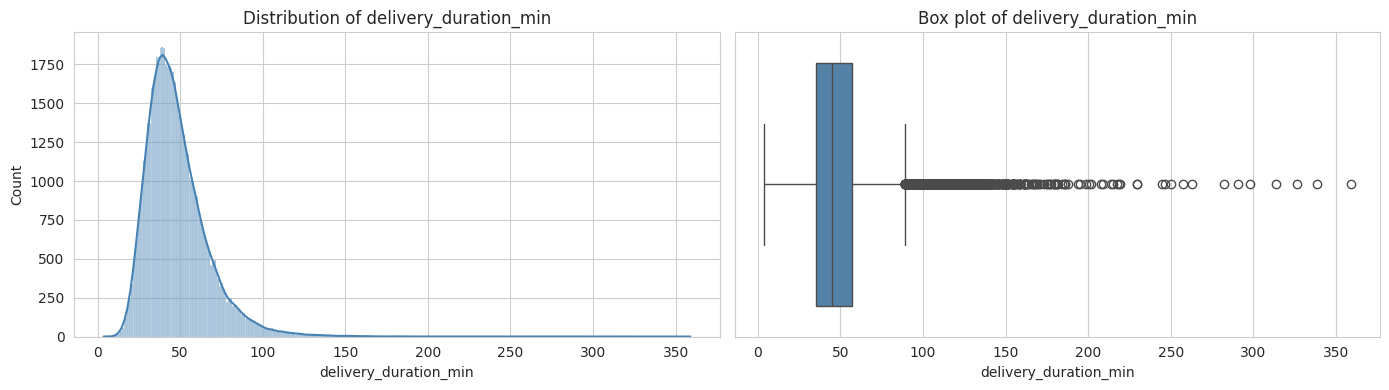

Skewness of target: 1.905


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df[target], kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Distribution of delivery_duration_min")
sns.boxplot(x=df[target], ax=ax[1], color="steelblue")
ax[1].set_title("Box plot of delivery_duration_min")
plt.tight_layout(); plt.show()
print(f"Skewness of target: {df[target].skew():.3f}")

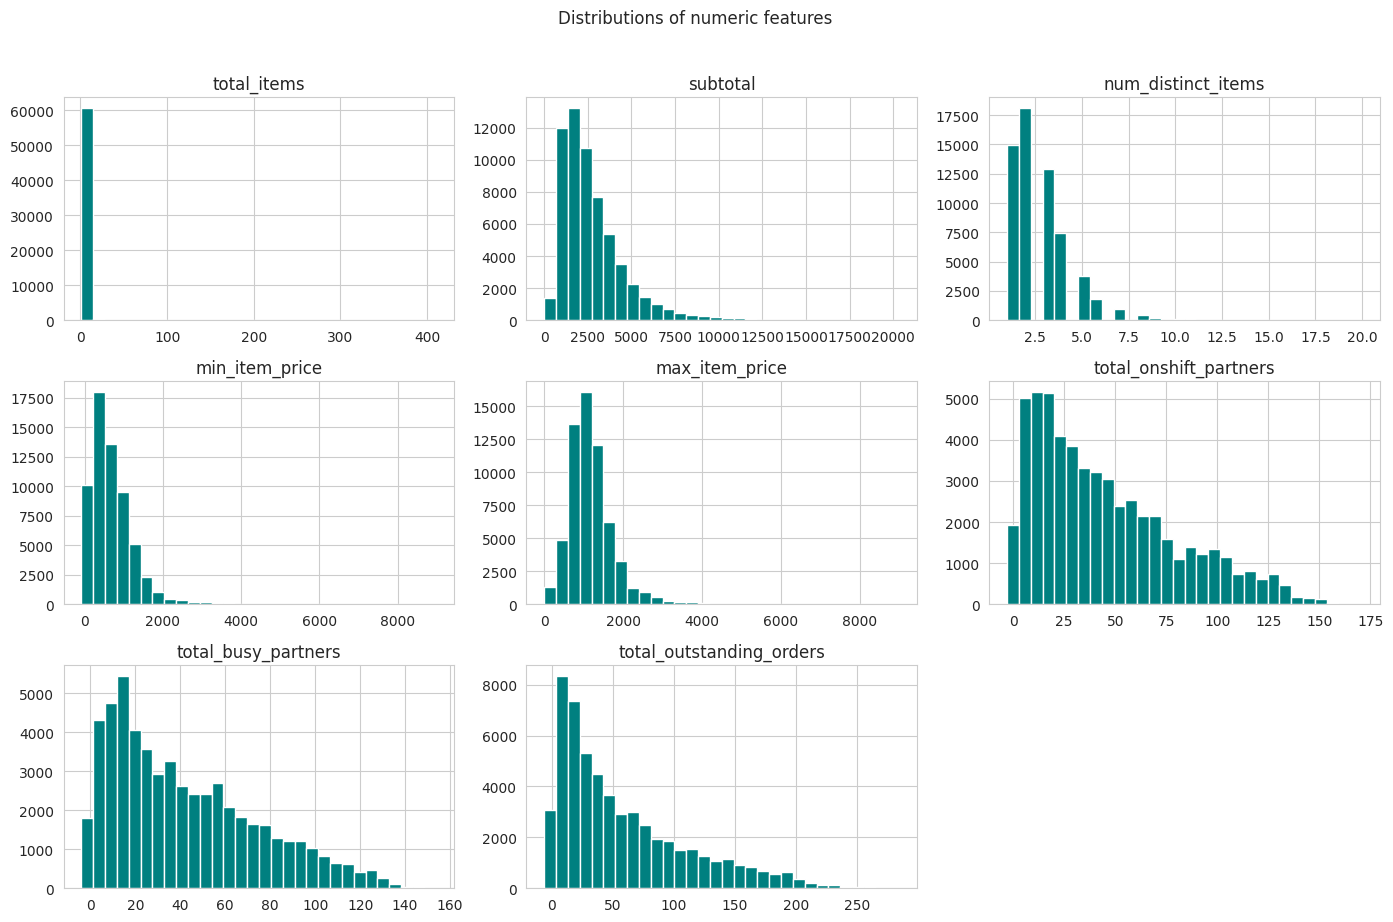

In [ ]:
# 3b. Histograms of all numeric features
df[numeric_cols].hist(bins=30, figsize=(14, 9), color="teal", edgecolor="white")
plt.suptitle("Distributions of numeric features", y=1.02)
plt.tight_layout(); plt.show()

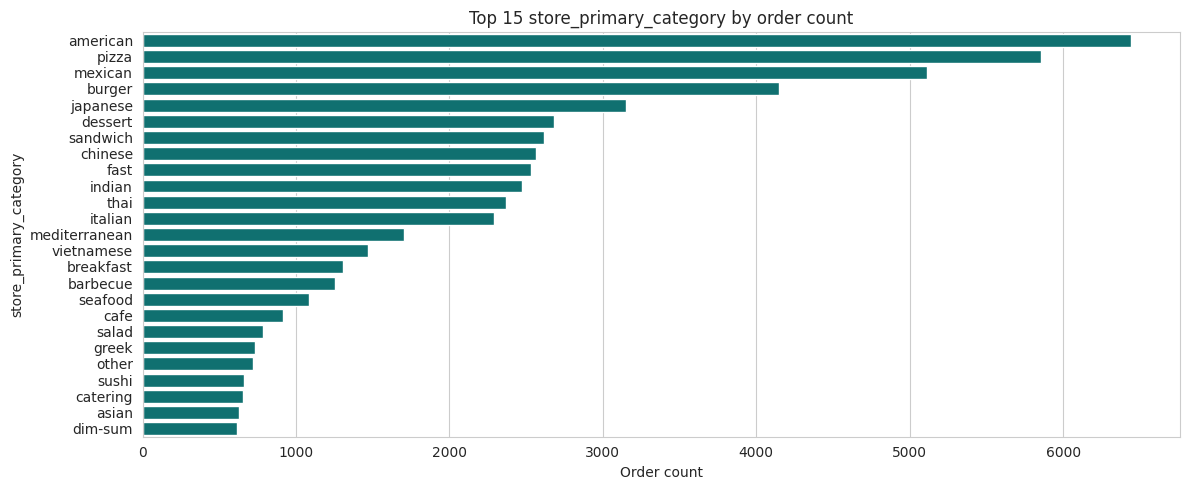

In [ ]:
# 3c. Count plot for store_primary_category (top 15 only - likely high cardinality)
top_categories = df["store_primary_category"].value_counts().head(25)
plt.figure(figsize=(12, 5))
sns.barplot(x=top_categories.values, y=top_categories.index, color="teal")
plt.title("Top 15 store_primary_category by order count")
plt.xlabel("Order count")
plt.tight_layout(); plt.show()

In [ ]:
df["store_primary_category"].nunique()

70

In [ ]:
top_categories_full = df["store_primary_category"].value_counts()
top15_share = top_categories_full.head(15).sum() / top_categories_full.sum()
top20_share = top_categories_full.head(20).sum() / top_categories_full.sum()
top25_share = top_categories_full.head(25).sum() / top_categories_full.sum()
print(f"Top 15 categories cover {top15_share*100:.1f}% of all orders")
print(f"Top 20 categories cover {top20_share*100:.1f}% of all orders")
print(f"Top 25 categories cover {top25_share*100:.1f}% of all orders")

Top 15 categories cover 78.6% of all orders
Top 20 categories cover 86.6% of all orders
Top 25 categories cover 92.1% of all orders


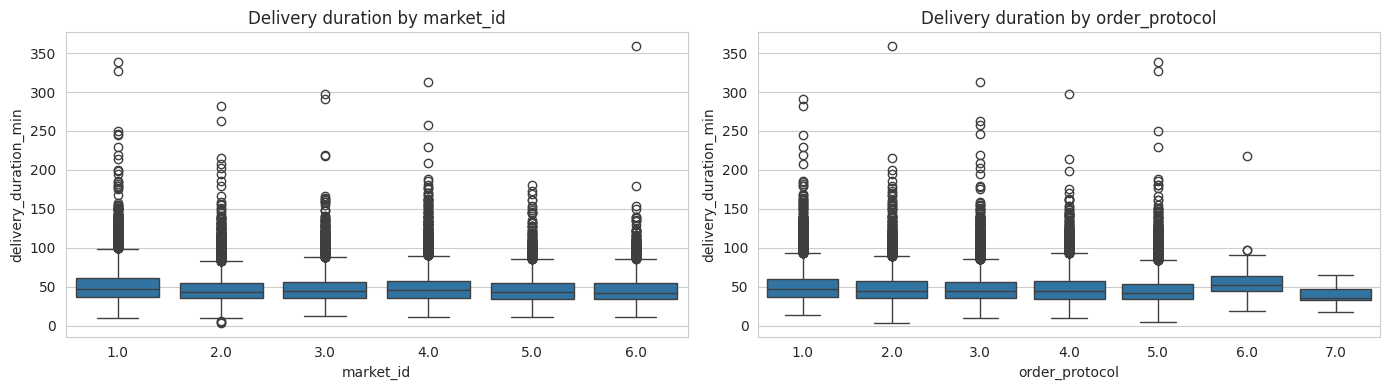

In [ ]:
# 3d. Premium/duration by market_id and order_protocol
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x="market_id", y=target, data=df, ax=axes[0])
axes[0].set_title("Delivery duration by market_id")
sns.boxplot(x="order_protocol", y=target, data=df, ax=axes[1])
axes[1].set_title("Delivery duration by order_protocol")
plt.tight_layout(); plt.show()

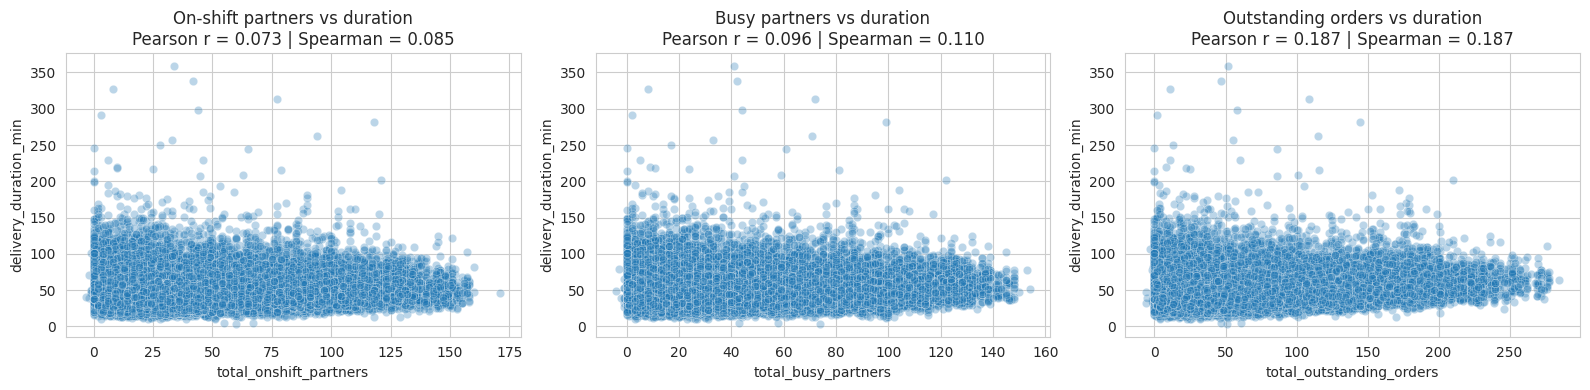

In [ ]:
# 3e. Operational load vs delivery duration, with Pearson (and Spearman) correlation
load_cols = ["total_onshift_partners", "total_busy_partners", "total_outstanding_orders"]
titles = ["On-shift partners vs duration", "Busy partners vs duration", "Outstanding orders vs duration"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, load_cols, titles):
    # .dropna() because these columns still have missing values before cleaning
    pair = df[[col, target]].dropna()
    r_pearson, p_pearson = stats.pearsonr(pair[col], pair[target])
    r_spearman, _ = stats.spearmanr(pair[col], pair[target])

    sns.scatterplot(x=col, y=target, data=pair, alpha=0.3, ax=ax)
    ax.set_title(f"{title}\nPearson r = {r_pearson:.3f} | Spearman = {r_spearman:.3f}")
plt.tight_layout(); plt.show()

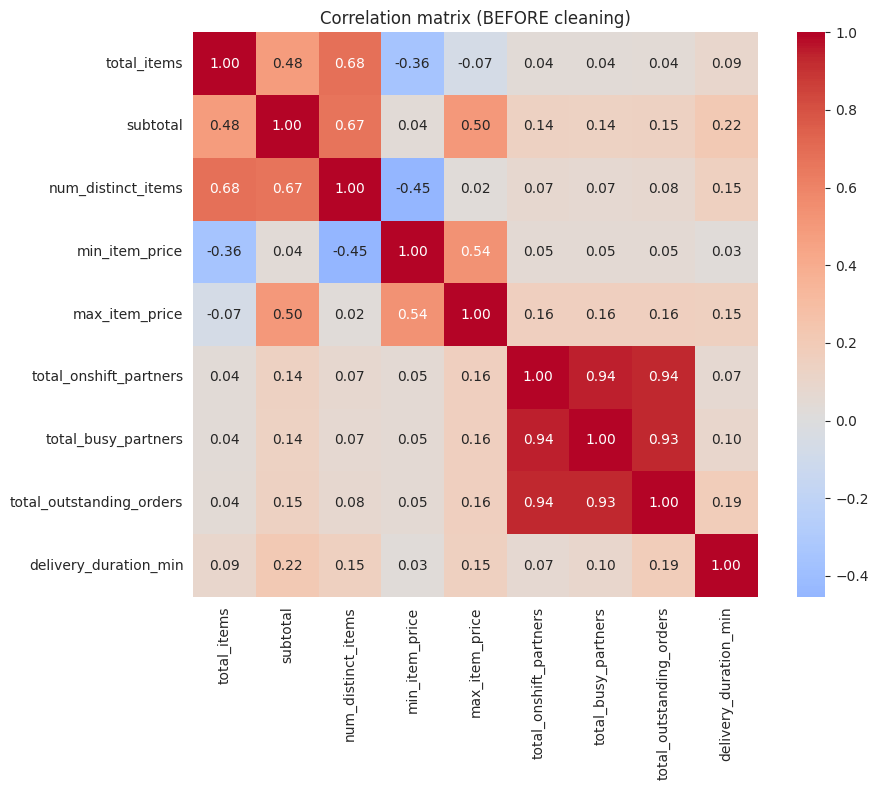

,delivery_duration_min
subtotal,0.219094
total_outstanding_orders,0.186902
max_item_price,0.151674
num_distinct_items,0.151353
total_busy_partners,0.095970
total_items,0.093326
total_onshift_partners,0.073171
min_item_price,0.030693


In [ ]:
# 4. Correlations BEFORE cleaning
corr_before = df[numeric_cols + [target]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_before, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (BEFORE cleaning)")
plt.tight_layout(); plt.show()

corr_before[target].drop(target).sort_values(key=abs, ascending=False)

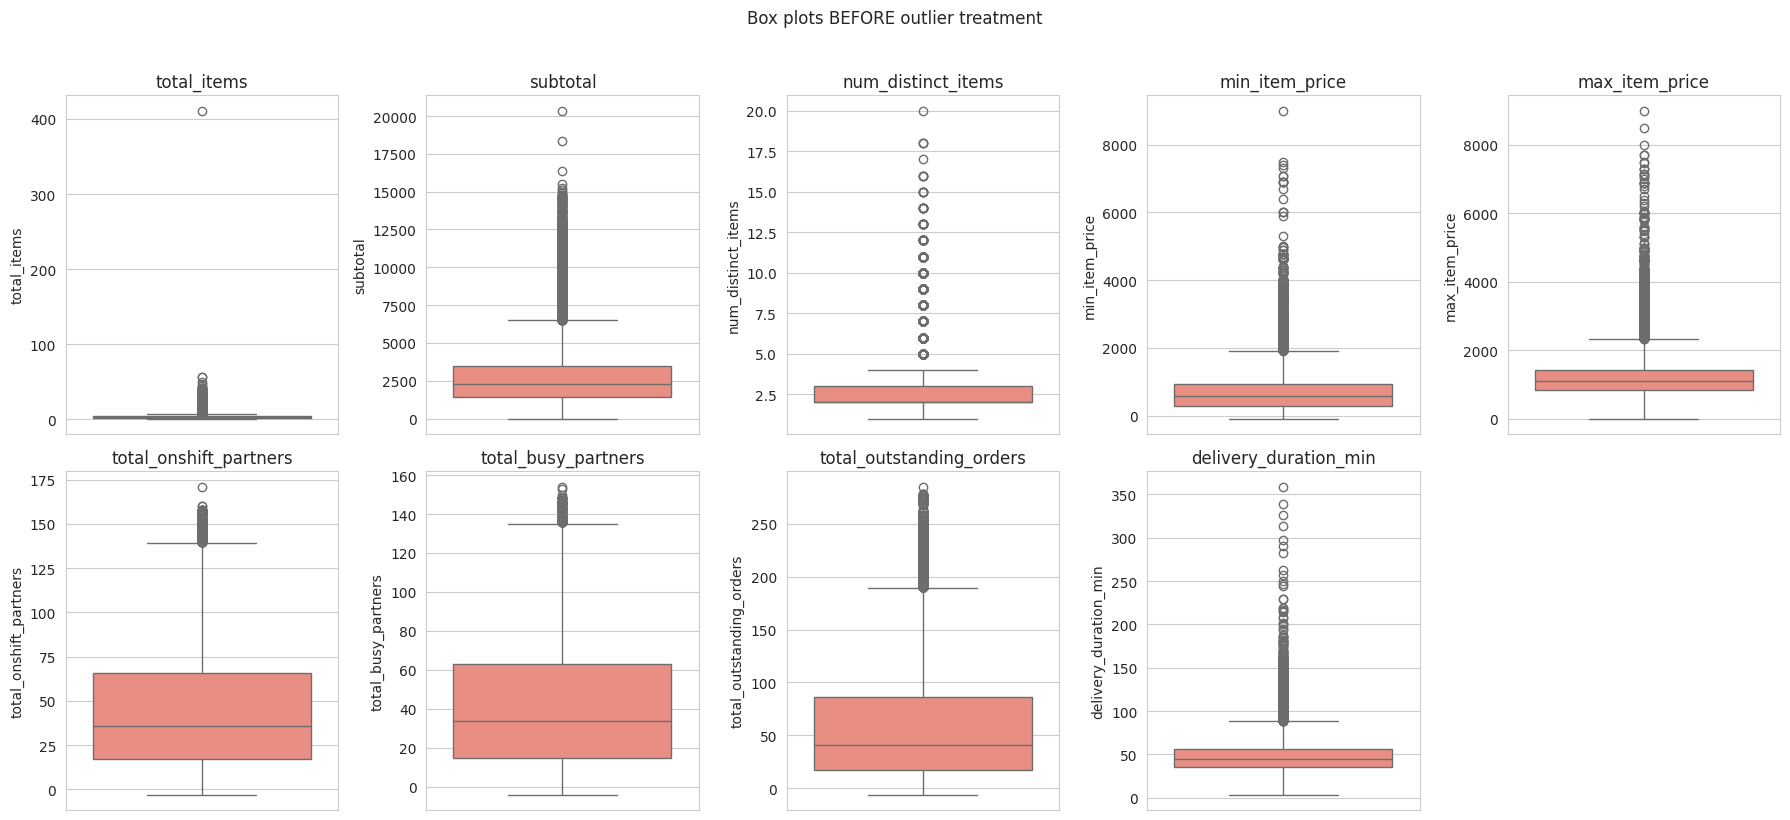

In [ ]:
# 5. Outlier detection - IQR method and box plots
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

outlier_report = []
for col in numeric_cols + [target]:
    lower, upper = iqr_bounds(df[col])
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_report.append([col, round(lower, 1), round(upper, 1), int(n_out)])
pd.DataFrame(outlier_report, columns=["feature", "lower_bound", "upper_bound", "n_outliers"])

cols_to_plot = numeric_cols + [target]
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cols_to_plot):
    sns.boxplot(y=df[col], ax=ax, color="salmon")
    ax.set_title(col)
for ax in axes.ravel()[len(cols_to_plot):]:
    ax.axis("off")
plt.suptitle("Box plots BEFORE outlier treatment", y=1.02)
plt.tight_layout(); plt.show()

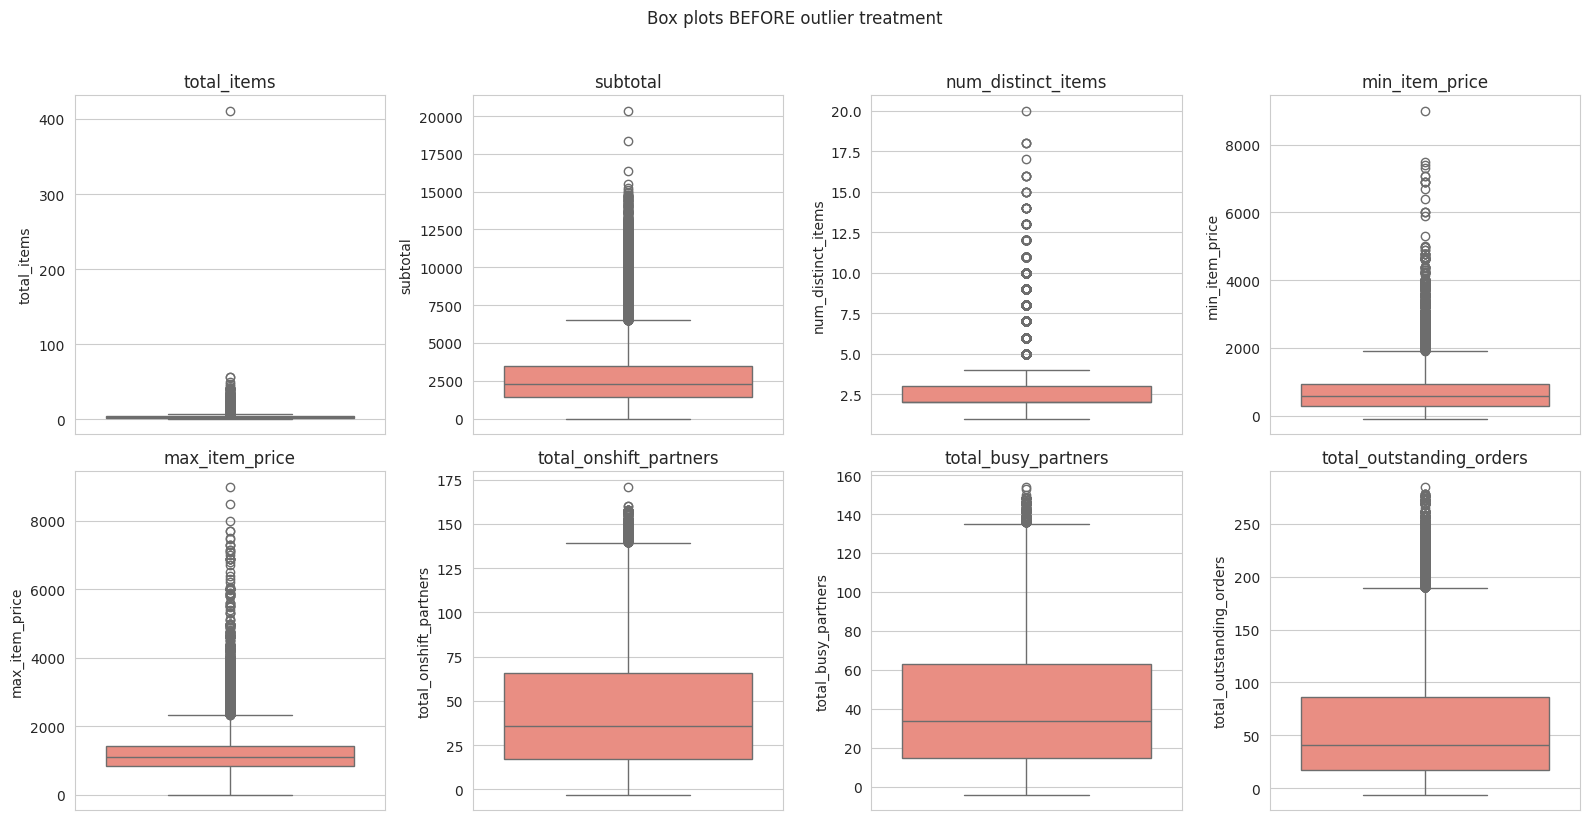

In [ ]:
# 5b. Box plots make the outliers visible at a glance
cols_to_plot = numeric_cols + [target]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cols_to_plot):
    sns.boxplot(y=df[col], ax=ax, color="salmon")
    ax.set_title(col)
# hide any unused subplot
for ax in axes.ravel()[len(cols_to_plot):]:
    ax.axis("off")
plt.suptitle("Box plots BEFORE outlier treatment", y=1.02)
plt.tight_layout(); plt.show()

Cap FEATURES at IQR bounds
NOTE: We deliberately do NOT cap the target (delivery_duration_min) here.
 A genuinely long delivery (bad weather, far distance, restaurant delay)
is real business signal Porter needs to predict, not noise to suppress.
Capping the target would make the model systematically underpredict the
slowest deliveries - exactly the ones customers complain about most.
We instead remove clearly IMPOSSIBLE target rows (negative, or absurdly
long e.g. > 4 hours, which are almost certainly data/logging errors).

In [ ]:
df_capped = df.copy()
df_capped = df_capped[(df_capped[target] > 0) & (df_capped[target] <= 240)].copy()
print(f"Rows remaining after removing impossible target values: {len(df_capped)} "
      f"(dropped {len(df) - len(df_capped)})")

Rows remaining after removing impossible target values: 61041 (dropped 12)


In [ ]:
for col in numeric_cols:
    lower, upper = iqr_bounds(df_capped[col])
    df_capped[col] = df_capped[col].clip(lower=lower, upper=upper)
after = []
for col in numeric_cols:
    lower, upper = iqr_bounds(df_capped[col])
    after.append([col, int(((df_capped[col] < lower) | (df_capped[col] > upper)).sum())])
print("Remaining IQR-flagged points after capping features (small residual counts are normal):")
pd.DataFrame(after, columns=["feature", "n_outliers_after"])

Remaining IQR-flagged points after capping features (small residual counts are normal):


,feature,n_outliers_after
0,total_items,0
1,subtotal,0
2,num_distinct_items,0
3,min_item_price,0
4,max_item_price,0
5,total_onshift_partners,0
6,total_busy_partners,0
7,total_outstanding_orders,0


# 6. Missing-value imputation

Categorical -> mode. Numeric -> KNN. (Same rationale as the insurance case:
KNN respects the multivariate structure, e.g. a missing max_item_price can be inferred from num_distinct_items and subtotal for similar orders.)

In [ ]:
df_clean = df_capped.copy()

In [ ]:
# store_primary_category can have missing values (unclassified restaurants)
mode_imputer = SimpleImputer(strategy="most_frequent")
df_clean[["store_primary_category"]] = mode_imputer.fit_transform(df_clean[["store_primary_category"]])

In [ ]:
# store_id and order_protocol are categorical codes - also mode-impute if missing
for col in ["market_id","order_protocol"]:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

knn_imputer = KNNImputer(n_neighbors=5, weights="distance")
df_clean[numeric_cols] = knn_imputer.fit_transform(df_clean[numeric_cols])

assert df_clean[numeric_cols + ["store_primary_category", "market_id", "order_protocol"]].isna().sum().sum() == 0, \
    "There are still missing values!"
print("No missing values remain in modeling columns. Cleaning complete.")

No missing values remain in modeling columns. Cleaning complete.


# 7. Feature engineering from created_at
Time-of-day and day-of-week strongly affect delivery time (rush hour, weekend demand) but a raw timestamp is useless to a linear model - it has to be decomposed into cyclical/categorical pieces.

In [ ]:
df_clean["order_hour"] = df_clean["created_at"].dt.hour
df_clean["order_dayofweek"] = df_clean["created_at"].dt.dayofweek  # 0=Mon
df_clean["is_weekend"] = df_clean["order_dayofweek"].isin([5, 6]).astype(int)

In [ ]:
# Bucket hour into a coarser, more linearly-usable "part of day" category
def part_of_day(h):
    if 6 <= h < 11: return "morning"
    if 11 <= h < 15: return "lunch"
    if 15 <= h < 18: return "afternoon"
    if 18 <= h < 22: return "dinner"
    return "late_night"
df_clean["part_of_day"] = df_clean["order_hour"].apply(part_of_day)

In [ ]:
df_clean.head()

,market_id,created_at,actual_delivery_time,store_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders,delivery_duration_min,order_hour,order_dayofweek,is_weekend,part_of_day
0,1.0,2015-02-06 22:24:17,2015-02-06 23:27:16,df263d996281d984952c07998dc54358,american,1.0,4.0,3441.0,4.0,557.0,1239.0,33.0,14.0,21.0,62.983333,22,4,0,late_night
1,2.0,2015-02-10 21:49:25,2015-02-10 22:56:29,f0ade77b43923b38237db569b016ba25,mexican,2.0,1.0,1900.0,1.0,1400.0,1400.0,1.0,2.0,2.0,67.066667,21,1,0,dinner
2,3.0,2015-01-22 20:39:28,2015-01-22 21:09:09,f0ade77b43923b38237db569b016ba25,american,1.0,1.0,1900.0,1.0,1900.0,1900.0,1.0,0.0,0.0,29.683333,20,3,0,dinner
3,3.0,2015-02-03 21:21:45,2015-02-03 22:13:00,f0ade77b43923b38237db569b016ba25,american,1.0,6.0,6525.0,4.5,600.0,1800.0,1.0,1.0,2.0,51.250000,21,1,0,dinner
4,3.0,2015-02-15 02:40:36,2015-02-15 03:20:26,f0ade77b43923b38237db569b016ba25,american,1.0,3.0,3900.0,3.0,1100.0,1600.0,6.0,6.0,9.0,39.833333,2,6,1,late_night


**Operational-load ratios often carry more signal than the raw counts**:
what fraction of on-shift partners are actually busy, and how many outstanding orders exist per available (free) partner.

In [ ]:
df_clean["busy_ratio"] = df_clean["total_busy_partners"] / df_clean["total_onshift_partners"].replace(0, np.nan)
df_clean["busy_ratio"] = df_clean["busy_ratio"].fillna(df_clean["busy_ratio"].median()).clip(0, 1)

In [ ]:
free_partners = (df_clean["total_onshift_partners"] - df_clean["total_busy_partners"]).clip(lower=0)
df_clean["orders_per_free_partner"] = df_clean["total_outstanding_orders"] / (free_partners + 1)  # +1 avoids /0

**High-cardinality** store_id -> frequency encoding (count of orders from that store). One-hot would create thousands of sparse columns; frequency encoding keeps it as a single informative numeric feature.

In [ ]:
store_freq = df_clean["store_id"].value_counts()
df_clean["store_order_frequency"] = df_clean["store_id"].map(store_freq)
print(store_freq)

store_id
d43ab110ab2489d6b9b2caa394bf920f    936
757b505cfd34c64c85ca5b5690ee5293    863
f7177163c833dff4b38fc8d2872f1ec6    536
149e9677a5989fd342ae44213df68868    529
6e2eec9ca19c076736d19ac5426473af    478
                                   ... 
e5e6851e7f7ffd3530e7389e183aa468      1
197e342c9fbad962dbe6d3322f723ca6      1
5401acfe633e6817b508b84d23686743      1
df263d996281d984952c07998dc54358      1
4e                                    1
Name: count, Length: 2177, dtype: int64


In [ ]:
engineered_numeric_cols = numeric_cols + ["busy_ratio", "orders_per_free_partner", "store_order_frequency"]
print("Engineered numeric features added:", ["busy_ratio", "orders_per_free_partner", "store_order_frequency"])

Engineered numeric features added: ['busy_ratio', 'orders_per_free_partner', 'store_order_frequency']


# 8. Data statistics AFTER cleaning

In [ ]:
df_clean[engineered_numeric_cols + [target]].describe().T

compare = pd.DataFrame({
    "mean_before": df[numeric_cols + [target]].mean(),
    "mean_after":  df_clean[numeric_cols + [target]].mean(),
    "std_before":  df[numeric_cols + [target]].std(),
    "std_after":   df_clean[numeric_cols + [target]].std(),
    "min_before": df[numeric_cols + [target]].min(),
    "min_after": df_clean[numeric_cols + [target]].min(),
    "max_before": df[numeric_cols + [target]].max(),
    "max_after": df_clean[numeric_cols + [target]].max()
}).round(2)
compare

,mean_before,mean_after,std_before,std_after,min_before,min_after,max_before,max_after
total_items,3.27,3.05,3.09,1.78,1.00,1.00,411.00,7.00
subtotal,2742.45,2652.56,1852.44,1553.27,0.00,0.00,20350.00,6525.00
num_distinct_items,2.71,2.52,1.66,1.20,1.00,1.00,20.00,4.50
min_item_price,689.78,670.34,541.29,463.91,-86.00,-86.00,8999.00,1920.00
max_item_price,1190.26,1162.98,585.26,486.39,0.00,0.00,8999.00,2335.00
total_onshift_partners,44.84,44.67,34.87,33.71,-3.00,-3.00,171.00,139.50
total_busy_partners,41.82,41.70,32.47,31.47,-4.00,-4.00,154.00,135.00
total_outstanding_orders,58.44,57.64,53.41,50.10,-6.00,-6.00,285.00,189.50
delivery_duration_min,48.03,47.99,18.83,18.52,3.72,3.72,358.93,229.68


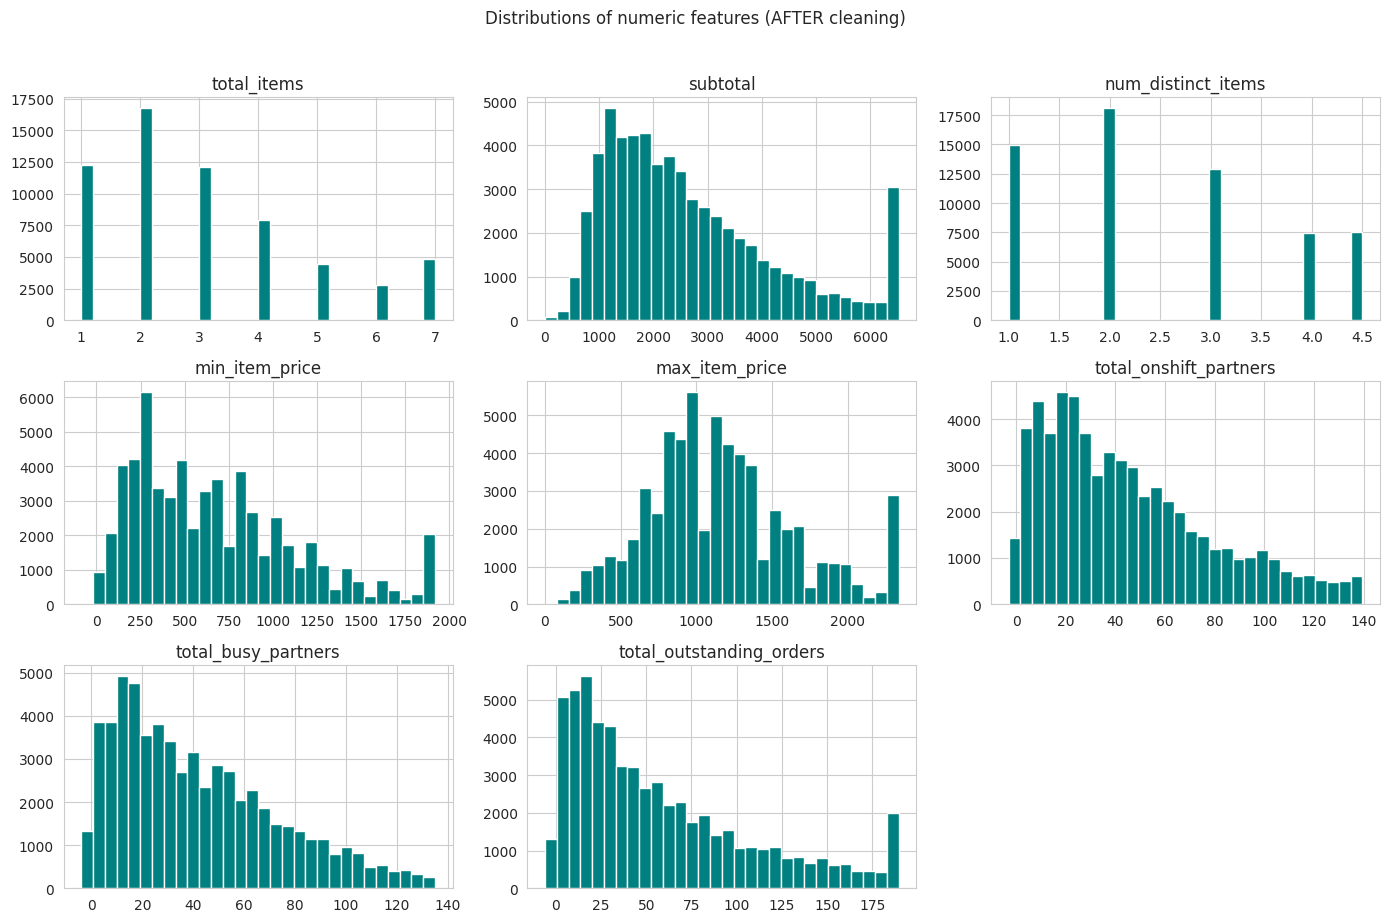

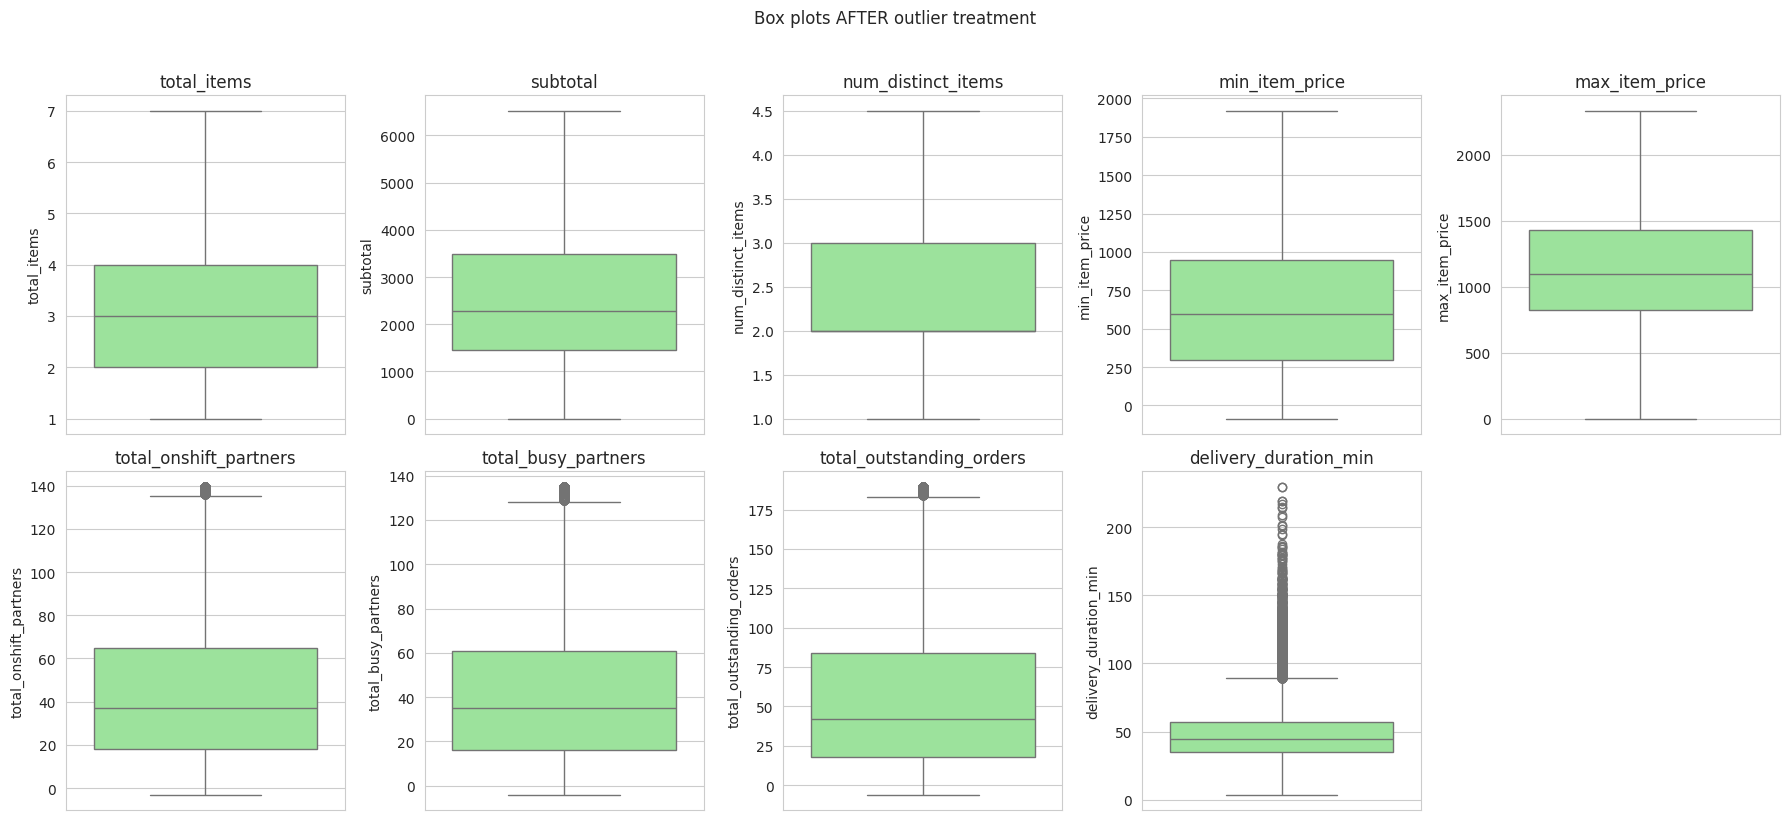

In [ ]:
# 8b. EDA re-check after cleaning
df_clean[numeric_cols].hist(bins=30, figsize=(14, 9), color="teal", edgecolor="white")
plt.suptitle("Distributions of numeric features (AFTER cleaning)", y=1.02)
plt.tight_layout(); plt.show()

cols_to_plot = numeric_cols + [target]
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cols_to_plot):
    sns.boxplot(y=df_clean[col], ax=ax, color="lightgreen")
    ax.set_title(col)
for ax in axes.ravel()[len(cols_to_plot):]:
    ax.axis("off")
plt.suptitle("Box plots AFTER outlier treatment", y=1.02)
plt.tight_layout(); plt.show()

# 9. Correlations AFTER cleaning

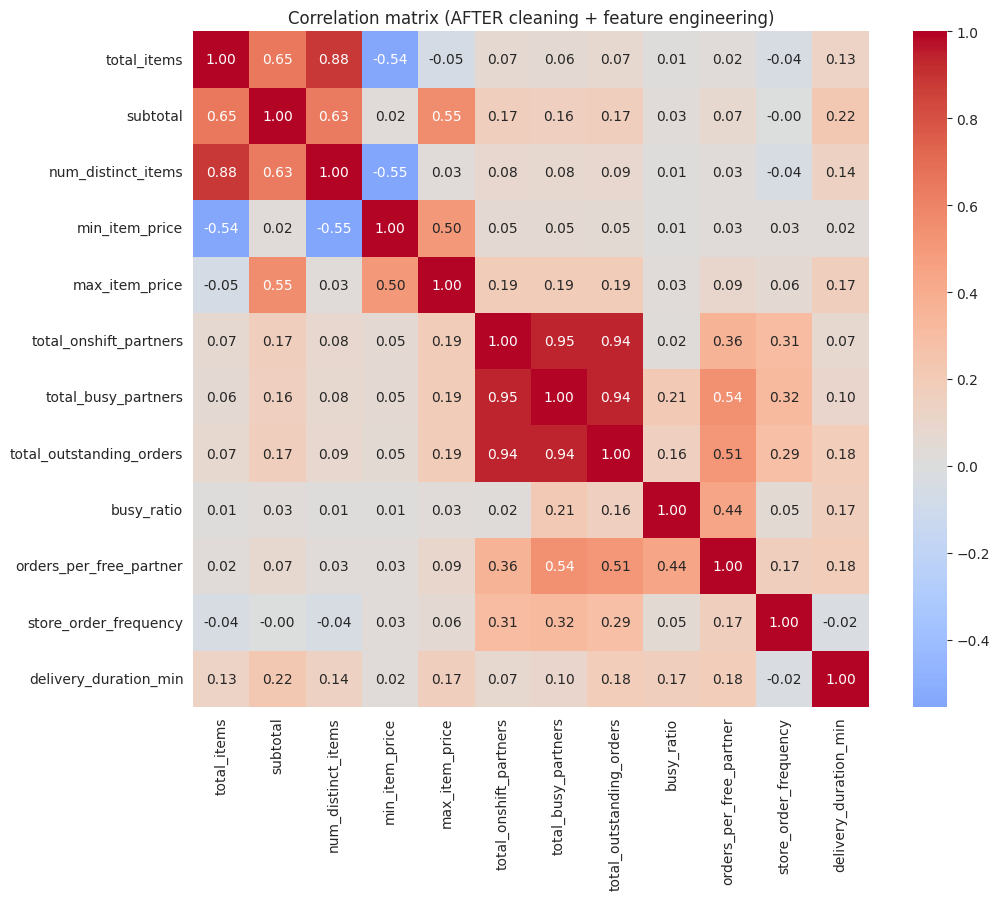

In [ ]:
corr_after = df_clean[engineered_numeric_cols + [target]].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr_after, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (AFTER cleaning + feature engineering)")
plt.tight_layout(); plt.show()

In [ ]:
corr_target = corr_after[target].drop(target).sort_values(key=abs, ascending=False)
print("Correlation of each numeric feature with delivery_duration_min:")
corr_target

Correlation of each numeric feature with delivery_duration_min:


,delivery_duration_min
subtotal,0.213736
total_outstanding_orders,0.173120
orders_per_free_partner,0.169697
busy_ratio,0.169619
num_distinct_items,0.150481
max_item_price,0.143648
total_items,0.140530
total_busy_partners,0.088462
total_onshift_partners,0.069529
store_order_frequency,-0.038526


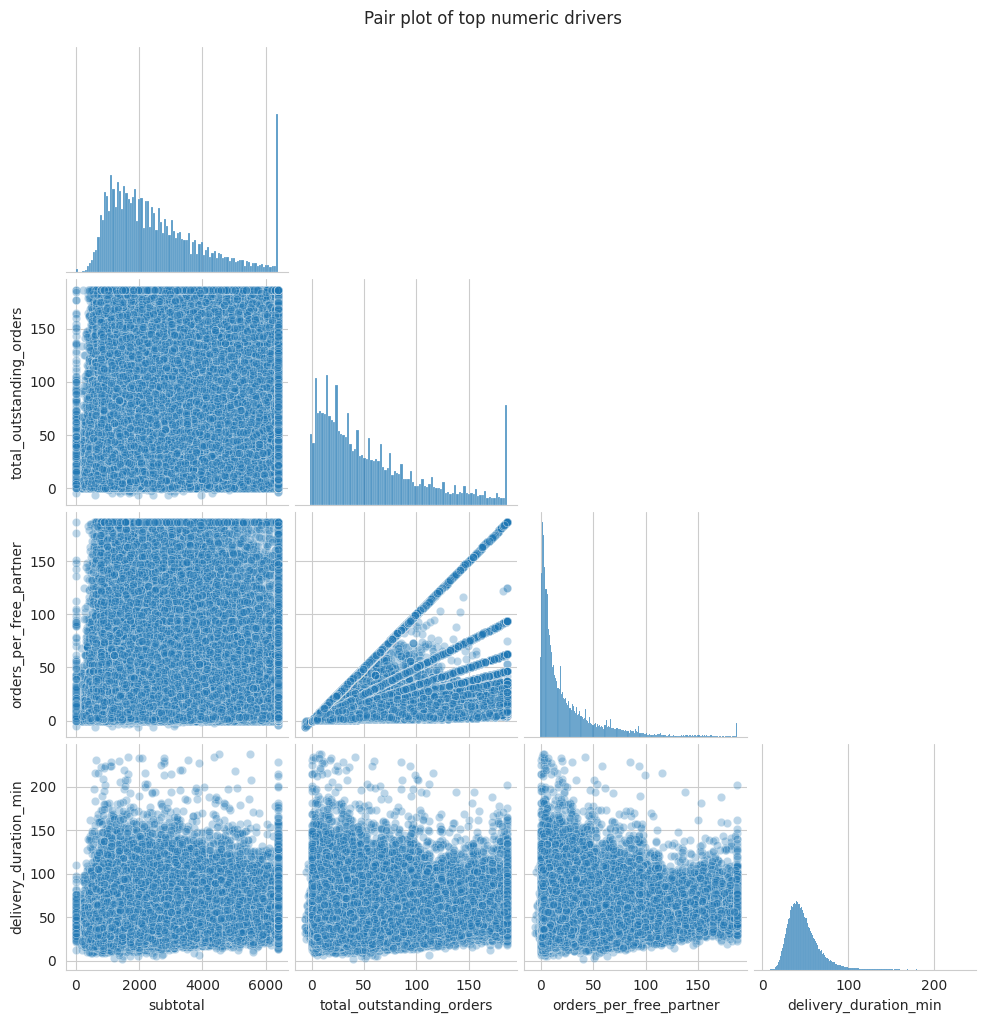

In [ ]:
top_feats = corr_target.head(3).index.tolist()
sns.pairplot(df_clean[top_feats + [target]], corner=True, plot_kws={"alpha": 0.3})
plt.suptitle("Pair plot of top numeric drivers", y=1.02)
plt.show()

# 10. Hypothesis testing on categorical variables

In [ ]:
# ANOVA: does duration differ across store_id / order_protocol / part_of_day / store category?
for col in ["market_id","order_protocol", "part_of_day"]:
    groups = [g[target].values for _, g in df_clean.groupby(col)]
    f_stat, p_val = stats.f_oneway(*groups)
    print(f"ANOVA  {col}:  F = {f_stat:.3f},  p = {p_val:.3e}",
          "-> SIGNIFICANT (keep feature)" if p_val < 0.05 else "-> not significant")

ANOVA  market_id:  F = 406.143,  p = 0.000e+00 -> SIGNIFICANT (keep feature)
ANOVA  order_protocol:  F = 321.939,  p = 0.000e+00 -> SIGNIFICANT (keep feature)
ANOVA  part_of_day:  F = 858.429,  p = 0.000e+00 -> SIGNIFICANT (keep feature)


In [ ]:
# Weekend vs weekday - two-sample t-test
weekend = df_clean.loc[df_clean["is_weekend"] == 1, target]
weekday = df_clean.loc[df_clean["is_weekend"] == 0, target]
t_stat, p_val = stats.ttest_ind(weekend, weekday, equal_var=False)
print(f"\nT-TEST  weekend vs weekday")
print(f"  mean duration - weekend : {weekend.mean():.1f} min")
print(f"  mean duration - weekday : {weekday.mean():.1f} min")
print(f"  t = {t_stat:.3f},  p = {p_val:.3e}",
      "-> SIGNIFICANT" if p_val < 0.05 else "-> not significant")


T-TEST  weekend vs weekday
  mean duration - weekend : 49.2 min
  mean duration - weekday : 46.7 min
  t = 28.702,  p = 1.206e-180 -> SIGNIFICANT


In [ ]:
# Chi-square: is order_protocol associated with market_id (potential confound)?
ct = pd.crosstab(df_clean["order_protocol"], df_clean["market_id"])
chi2, p_val, dof, expected = stats.chi2_contingency(ct)
print(f"\nCHI-SQUARE  order_protocol vs market_id:  chi2 = {chi2:.3f}, p = {p_val:.3e}",
      "-> associated (note possible confounding)" if p_val < 0.05 else "-> independent")


CHI-SQUARE  order_protocol vs market_id:  chi2 = 21820.602, p = 0.000e+00 -> associated (note possible confounding)


In [ ]:
# store_primary_category has too many levels for a clean ANOVA table print, but we still test it since it will be encoded as a feature.
top_cat_mask = df_clean["store_primary_category"].isin(top_categories.index)
groups = [g[target].values for _, g in df_clean[top_cat_mask].groupby("store_primary_category")]
f_stat, p_val = stats.f_oneway(*groups)
print(f"\nANOVA  store_primary_category (top 15 only):  F = {f_stat:.3f},  p = {p_val:.3e}",
      "-> SIGNIFICANT" if p_val < 0.05 else "-> not significant")


ANOVA  store_primary_category (top 15 only):  F = 120.014,  p = 0.000e+00 -> SIGNIFICANT


# 11. Encoding categorical variables

In [ ]:
df_enc = df_clean.copy()

In [ ]:
print(df_clean[["market_id", "order_protocol"]].isna().sum())

market_id         0
order_protocol    0
dtype: int64


In [ ]:
# order_protocol: low cardinality -> one-hot (they are codes, NOT ordinal, so we must not feed them in as raw integers -
#that would wrongly imply market 3 is "more" than market 1 in some linear sense).
df_enc["market_id"] = df_enc["market_id"].astype(int).astype(str)
df_enc["order_protocol"] = df_enc["order_protocol"].astype(int).astype(str)

In [ ]:
#store_primary_category: collapse rare categories into "other" before
# one-hot, otherwise we get 50+ sparse dummy columns from long-tail categories.
top_20_cats = df_enc["store_primary_category"].value_counts().head(20).index
df_enc["store_primary_category"] = df_enc["store_primary_category"].where(
    df_enc["store_primary_category"].isin(top_20_cats), other="other"
)

categorical_for_encoding = ["market_id", "order_protocol", "store_primary_category", "part_of_day"]
df_enc = pd.get_dummies(df_enc, columns=categorical_for_encoding, drop_first=True, dtype=int)

model_feature_cols = (
    engineered_numeric_cols
    + ["order_hour", "order_dayofweek", "is_weekend"]
    + [c for c in df_enc.columns if c.startswith(tuple(f"{c}_" for c in categorical_for_encoding))]
)
print(f"Total modeling features after encoding: {len(model_feature_cols)}")
print(model_feature_cols)

Total modeling features after encoding: 48
['total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_partners', 'total_busy_partners', 'total_outstanding_orders', 'busy_ratio', 'orders_per_free_partner', 'store_order_frequency', 'order_hour', 'order_dayofweek', 'is_weekend', 'market_id_2', 'market_id_3', 'market_id_4', 'market_id_5', 'market_id_6', 'order_protocol_2', 'order_protocol_3', 'order_protocol_4', 'order_protocol_5', 'order_protocol_6', 'order_protocol_7', 'store_primary_category_barbecue', 'store_primary_category_breakfast', 'store_primary_category_burger', 'store_primary_category_chinese', 'store_primary_category_dessert', 'store_primary_category_fast', 'store_primary_category_greek', 'store_primary_category_indian', 'store_primary_category_italian', 'store_primary_category_japanese', 'store_primary_category_mediterranean', 'store_primary_category_mexican', 'store_primary_category_other', 'store_primary_category_pizza', 'store_prim

# 12. Train / test split and standard scaling

In [ ]:
X = df_enc[model_feature_cols]
y = df_enc[target]
feature_names = X.columns.tolist()
print(f"X shape: {X.shape},  y shape: {y.shape}")

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=RANDOM_STATE)
print(f"Train     : {X_train.shape[0]} rows")
print(f"Validation: {X_val.shape[0]} rows")
print(f"Test      : {X_test.shape[0]} rows")

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_names, index=X_train.index)
X_val_s   = pd.DataFrame(scaler.transform(X_val),       columns=feature_names, index=X_val.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),      columns=feature_names, index=X_test.index)

scaler_full = StandardScaler()
X_train_full_s = pd.DataFrame(scaler_full.fit_transform(X_train_full), columns=feature_names, index=X_train_full.index)
X_test_s2      = pd.DataFrame(scaler_full.transform(X_test),           columns=feature_names, index=X_test.index)
print("Scaling complete.")

X shape: (197363, 48),  y shape: (197363,)
Train     : 118417 rows
Validation: 39473 rows
Test      : 39473 rows
Scaling complete.


#13. Checking the assumptions of linear regression

                 feature       VIF
  total_onshift_partners 28.203307
     total_busy_partners 20.648023
total_outstanding_orders 13.252587
  part_of_day_late_night  8.320190
             total_items  8.069056
      part_of_day_dinner  7.317943
      num_distinct_items  6.211403
                subtotal  5.518557
              is_weekend  2.995284
         order_dayofweek  2.984739
          max_item_price  2.893036
              order_hour  2.605528
          min_item_price  2.542797
             market_id_2  2.459884
 orders_per_free_partner  2.333339

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.196
Model:                            OLS   Adj. R-squared:                  0.196
Method:                 Least Squares   F-statistic:                     602.9
Date:                Sat, 19 Sep 2026   Prob (F-statistic):               0.00
Time:                        02:47:27   Log-

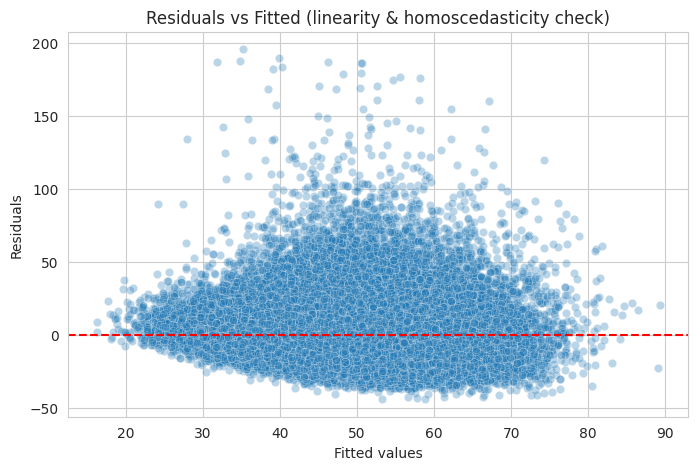

corr(fitted, residuals) = 0.0000 -> PASS
Durbin-Watson = 2.008 -> PASS
Breusch-Pagan p-value = 0.0000 -> NOTE: heteroscedasticity likely (delivery times often have larger errors during busy periods - the variance itself may depend on load, which is a real operational finding, not just a nuisance)
Jarque-Bera p-value = 0.0000 -> NOTE: residuals deviate from normality (common at scale)


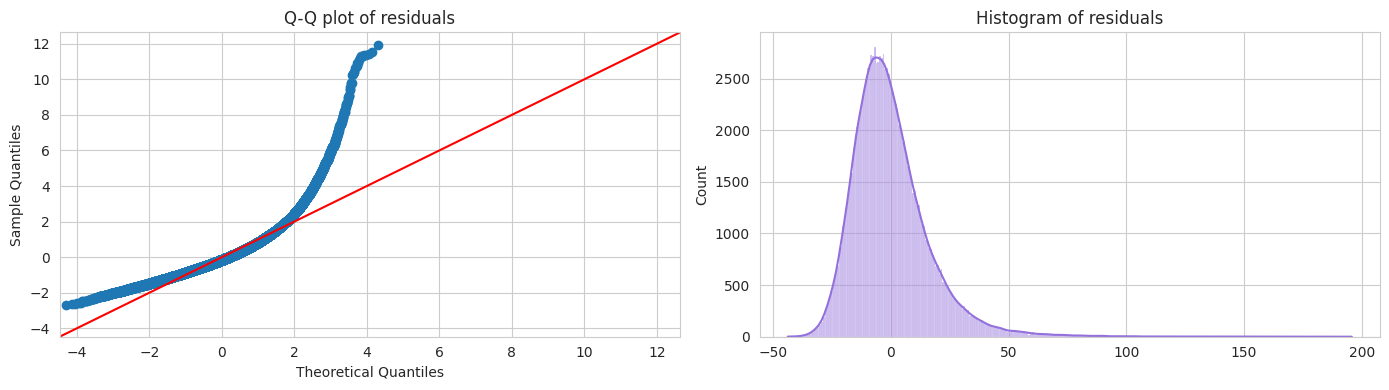

In [ ]:
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
vif_df = pd.DataFrame({
    "feature": feature_names,
    "VIF": [variance_inflation_factor(X_train_s.values, i) for i in range(X_train_s.shape[1])]
}).sort_values("VIF", ascending=False)
print(vif_df.head(15).to_string(index=False))

if (vif_df["VIF"] < 10).all():
    print("\nPASS: No feature has VIF >= 10 -> multicollinearity acceptable.")
else:
    print("\nWARNING: Some features have VIF >= 10 - likely candidates: total_busy_partners vs "
          "total_onshift_partners vs busy_ratio, since busy_ratio is DERIVED from the other two. "
          "Consider dropping one of the raw partner counts once busy_ratio is included.")

X_train_sm = sm.add_constant(X_train_s)
ols = sm.OLS(y_train.values, X_train_sm).fit()
residuals = ols.resid
fitted = ols.fittedvalues
print(ols.summary())

plt.figure(figsize=(8, 5))
sns.scatterplot(x=fitted, y=residuals, alpha=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values"); plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (linearity & homoscedasticity check)")
plt.show()

lin_corr = np.corrcoef(fitted, residuals)[0, 1]
print(f"corr(fitted, residuals) = {lin_corr:.4f}",
      "-> PASS" if abs(lin_corr) < 0.1 else "-> WARNING: possible non-linearity")

dw = durbin_watson(residuals)
print(f"Durbin-Watson = {dw:.3f}",
      "-> PASS" if 1.5 < dw < 2.5 else "-> WARNING: possible autocorrelation")

bp_stat, bp_p, _, _ = het_breuschpagan(residuals, X_train_sm)
print(f"Breusch-Pagan p-value = {bp_p:.4f}",
      "-> PASS (homoscedastic)" if bp_p > 0.05 else "-> NOTE: heteroscedasticity likely "
      "(delivery times often have larger errors during busy periods - the variance itself "
      "may depend on load, which is a real operational finding, not just a nuisance)")

jb_stat, jb_p = stats.jarque_bera(residuals)[:2]
print(f"Jarque-Bera p-value = {jb_p:.4f}",
      "-> PASS" if jb_p > 0.05 else "-> NOTE: residuals deviate from normality (common at scale)")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sm.qqplot(residuals, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot of residuals")
sns.histplot(residuals, kde=True, ax=ax[1], color="mediumpurple")
ax[1].set_title("Histogram of residuals")
plt.tight_layout(); plt.show()

# 14. Building the linear model

Intercept: 47.61 minutes


/tmp/ipykernel_4440/51578194.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="coefficient", y="feature", data=coef_df.head(15), palette="vlag")


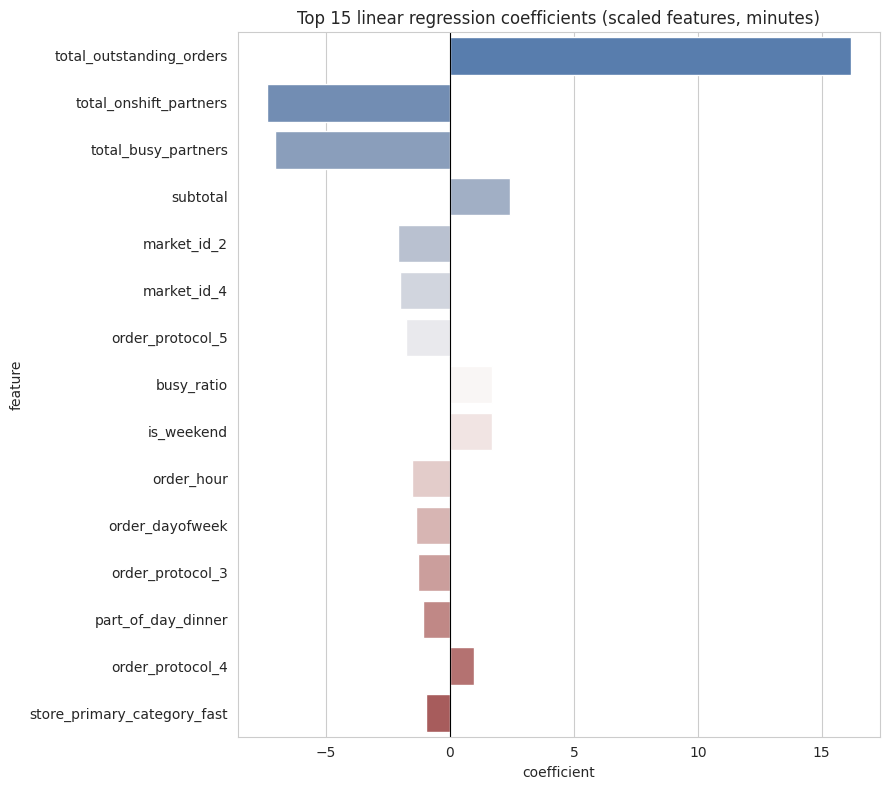

In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_s, y_train)

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": lin_reg.coef_
}).sort_values("coefficient", key=abs, ascending=False)
print(f"Intercept: {lin_reg.intercept_:,.2f} minutes")
coef_df.head(15)

plt.figure(figsize=(9, 8))
sns.barplot(x="coefficient", y="feature", data=coef_df.head(15), palette="vlag")
plt.title("Top 15 linear regression coefficients (scaled features, minutes)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout(); plt.show()

In [ ]:
print(type(lin_reg))
print(lin_reg)
print("Coefficients:", lin_reg.coef_)
print("Intercept:", lin_reg.intercept_)
print("Number of features it was trained on:", lin_reg.n_features_in_)

<class 'sklearn.linear_model._base.LinearRegression'>
LinearRegression()
Coefficients: [ 0.06319083  2.40356054  0.67417405  0.08337011  0.5963176  -7.37845155
 -7.06494723 16.17575343  1.70266135  0.4678377   0.27105956 -1.51222342
 -1.37705486  1.68231551 -2.09832924 -0.6246948  -1.99653125 -0.82926474
 -0.90015918 -0.45902581 -1.30763349  0.9824106  -1.77830525  0.66780446
 -0.02579943 -0.1442197  -0.25452931 -0.06483172 -0.15911068  0.32149541
 -0.96385603  0.04295707  0.09922574 -0.13576128  0.32281336 -0.08587372
 -0.41199188 -0.03206898  0.63740067  0.40452534  0.16887767 -0.08472282
 -0.11404712 -0.04351256 -1.09466982 -0.9426651   0.23646822 -0.58593715]
Intercept: 47.61016914801084
Number of features it was trained on: 48


# 15. Residual diagnostics on predictions (validation set)

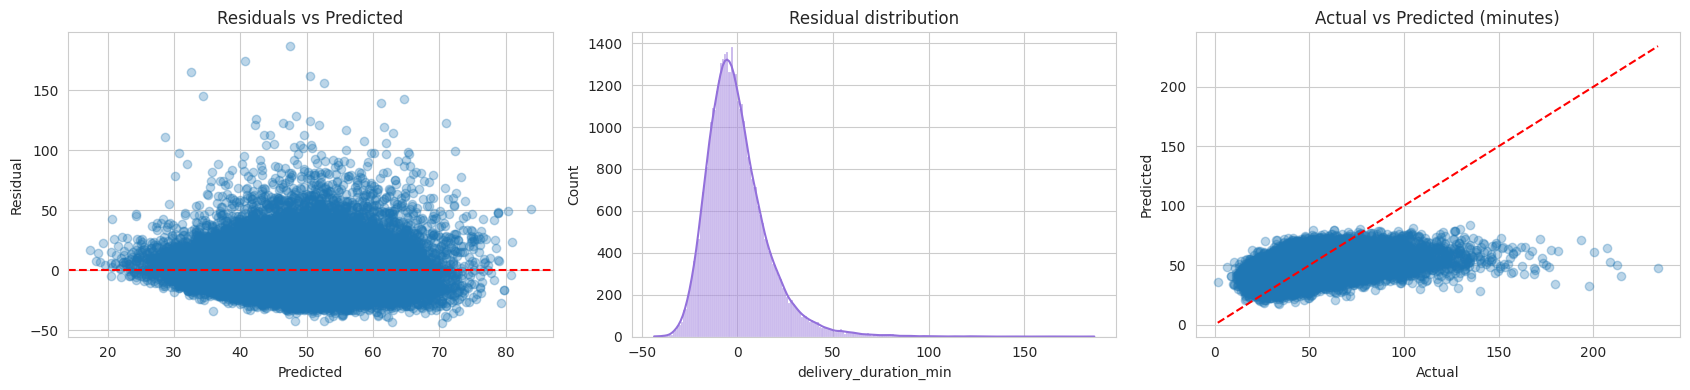

In [ ]:
val_pred = lin_reg.predict(X_val_s)
val_resid = y_val - val_pred

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].scatter(val_pred, val_resid, alpha=0.3); axes[0].axhline(0, color="red", ls="--")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs Predicted")
sns.histplot(val_resid, kde=True, ax=axes[1], color="mediumpurple"); axes[1].set_title("Residual distribution")
axes[2].scatter(y_val, val_pred, alpha=0.3)
lims = [min(y_val.min(), val_pred.min()), max(y_val.max(), val_pred.max())]
axes[2].plot(lims, lims, "r--"); axes[2].set_xlabel("Actual"); axes[2].set_ylabel("Predicted")
axes[2].set_title("Actual vs Predicted (minutes)")
plt.tight_layout(); plt.show()

# 16. Train / validation / test scoring and over/under-fitting check

In [ ]:
def report_scores(model, name):
    r2_tr = r2_score(y_train, model.predict(X_train_s))
    r2_va = r2_score(y_val,   model.predict(X_val_s))
    r2_te = r2_score(y_test,  model.predict(X_test_s))
    print(f"{name:16s}  train R2={r2_tr:.4f}   val R2={r2_va:.4f}   test R2={r2_te:.4f}")
    return r2_tr, r2_va, r2_te

r2_tr, r2_va, r2_te = report_scores(lin_reg, "LinearRegression")

if r2_tr - r2_va > 0.05:
    print("-> Signs of OVERFITTING.")
elif r2_tr < 0.3:
    print("-> Signs of UNDERFITTING (delivery time has irreducible randomness - traffic, "
          "weather, individual driver behavior - so even a good model may show moderate R2).")
else:
    print("-> Reasonable generalisation: scores are close across splits.")

cv_scores = cross_val_score(LinearRegression(), X_train_full_s, y_train_full, cv=5, scoring="r2")
print("5-fold CV R2 scores:", np.round(cv_scores, 4))
print(f"Mean CV R2 = {cv_scores.mean():.4f}  (+/- {cv_scores.std():.4f})")

test_pred = lin_reg.predict(X_test_s)
rmse = np.sqrt(mean_squared_error(y_test, test_pred))
mae  = mean_absolute_error(y_test, test_pred)
print(f"Test RMSE = {rmse:.2f} minutes")
print(f"Test MAE  = {mae:.2f} minutes")

LinearRegression  train R2=0.1965   val R2=0.2031   test R2=0.1956
-> Signs of UNDERFITTING (delivery time has irreducible randomness - traffic, weather, individual driver behavior - so even a good model may show moderate R2).
5-fold CV R2 scores: [0.1923 0.1918 0.201  0.197  0.2061]
Mean CV R2 = 0.1976  (+/- 0.0054)
Test RMSE = 16.43 minutes
Test MAE  = 12.02 minutes


# 17. Regularisation - Ridge, Lasso and Elastic Net

In [ ]:
ridge = Ridge(alpha=1.0, random_state=RANDOM_STATE).fit(X_train_s, y_train)
lasso = Lasso(alpha=1.0, random_state=RANDOM_STATE, max_iter=10000).fit(X_train_s, y_train)
enet  = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=RANDOM_STATE, max_iter=10000).fit(X_train_s, y_train)

for mdl, nm in [(lin_reg, "Linear"), (ridge, "Ridge"), (lasso, "Lasso"), (enet, "ElasticNet")]:
    report_scores(mdl, nm)

n_zeroed = (lasso.coef_ == 0).sum()
print(f"\nLasso zeroed out {n_zeroed} of {len(feature_names)} features "
      f"(likely candidates: rare one-hot categories, redundant partner-count features).")

def metrics_row(model, name):
    pred = model.predict(X_test_s)
    return {"model": name,
            "test_R2": r2_score(y_test, pred),
            "test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "test_MAE": mean_absolute_error(y_test, pred)}

summary = pd.DataFrame([
    metrics_row(lin_reg, "Linear"),
    metrics_row(ridge,   "Ridge"),
    metrics_row(lasso,   "Lasso"),
    metrics_row(enet,    "ElasticNet"),
]).round(3)
summary

Linear            train R2=0.1965   val R2=0.2031   test R2=0.1956
Ridge             train R2=0.1965   val R2=0.2031   test R2=0.1956
Lasso             train R2=0.0923   val R2=0.0942   test R2=0.0933
ElasticNet        train R2=0.1022   val R2=0.1040   test R2=0.1023

Lasso zeroed out 41 of 48 features (likely candidates: rare one-hot categories, redundant partner-count features).


,model,test_R2,test_RMSE,test_MAE
0,Linear,0.196,16.429,12.019
1,Ridge,0.196,16.429,12.019
2,Lasso,0.093,17.443,12.814
3,ElasticNet,0.102,17.356,12.743


# 18. R-squared, Adjusted R-squared, and Conclusion

In [ ]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

n_test = X_test_s.shape[0]
p = X_test_s.shape[1]
rows = []
for mdl, nm in [(lin_reg, "Linear"), (ridge, "Ridge"), (lasso, "Lasso"), (enet, "ElasticNet")]:
    r2v = r2_score(y_test, mdl.predict(X_test_s))
    rows.append({"model": nm, "R2": round(r2v, 4), "Adjusted_R2": round(adjusted_r2(r2v, n_test, p), 4)})
pd.DataFrame(rows)
print(rows)
print("""
CONCLUSION
----------
- Target had to be engineered (actual_delivery_time - created_at); this is the
  most important modeling decision in the whole pipeline.
- market_id, order_protocol were treated as categorical (one-hot), not ordinal
  numeric - a common mistake that silently corrupts linear models when skipped.
- Real-time operational load (on-shift/busy partners, outstanding orders, and
  the engineered busy_ratio / orders_per_free_partner) is expected to dominate
  as a predictor - delivery time is driven more by current network congestion
  than by what's in any single order.
- We did NOT cap the target at IQR bounds (unlike the insurance premium case)
  because unusually long deliveries are exactly the operational failures Porter
  needs the model to anticipate, not statistical noise to smooth away.
- Heteroscedasticity (variance increasing with load) is a plausible and
  informative finding here, not just an assumption violation to fix.

So, we can say that We built a model that predicts how long a delivery will take,
 using order details and how busy the delivery network is at that moment.
 On a typical order, our prediction is accurate to within about 12 minutes.
 The model is reliable for normal, everyday deliveries —
 but it's less accurate for unusually busy periods or unusually slow deliveries,
 so we'd recommend using it as a solid baseline ETA, with some buffer built in during peak times.
""")

[{'model': 'Linear', 'R2': 0.1956, 'Adjusted_R2': 0.1947}, {'model': 'Ridge', 'R2': 0.1956, 'Adjusted_R2': 0.1947}, {'model': 'Lasso', 'R2': 0.0933, 'Adjusted_R2': 0.0922}, {'model': 'ElasticNet', 'R2': 0.1023, 'Adjusted_R2': 0.1012}]

CONCLUSION
----------
- Target had to be engineered (actual_delivery_time - created_at); this is the
  most important modeling decision in the whole pipeline.
- market_id, order_protocol were treated as categorical (one-hot), not ordinal
  numeric - a common mistake that silently corrupts linear models when skipped.
- Real-time operational load (on-shift/busy partners, outstanding orders, and
  the engineered busy_ratio / orders_per_free_partner) is expected to dominate
  as a predictor - delivery time is driven more by current network congestion
  than by what's in any single order.
- We did NOT cap the target at IQR bounds (unlike the insurance premium case)
  because unusually long deliveries are exactly the operational failures Porter
  needs the mod